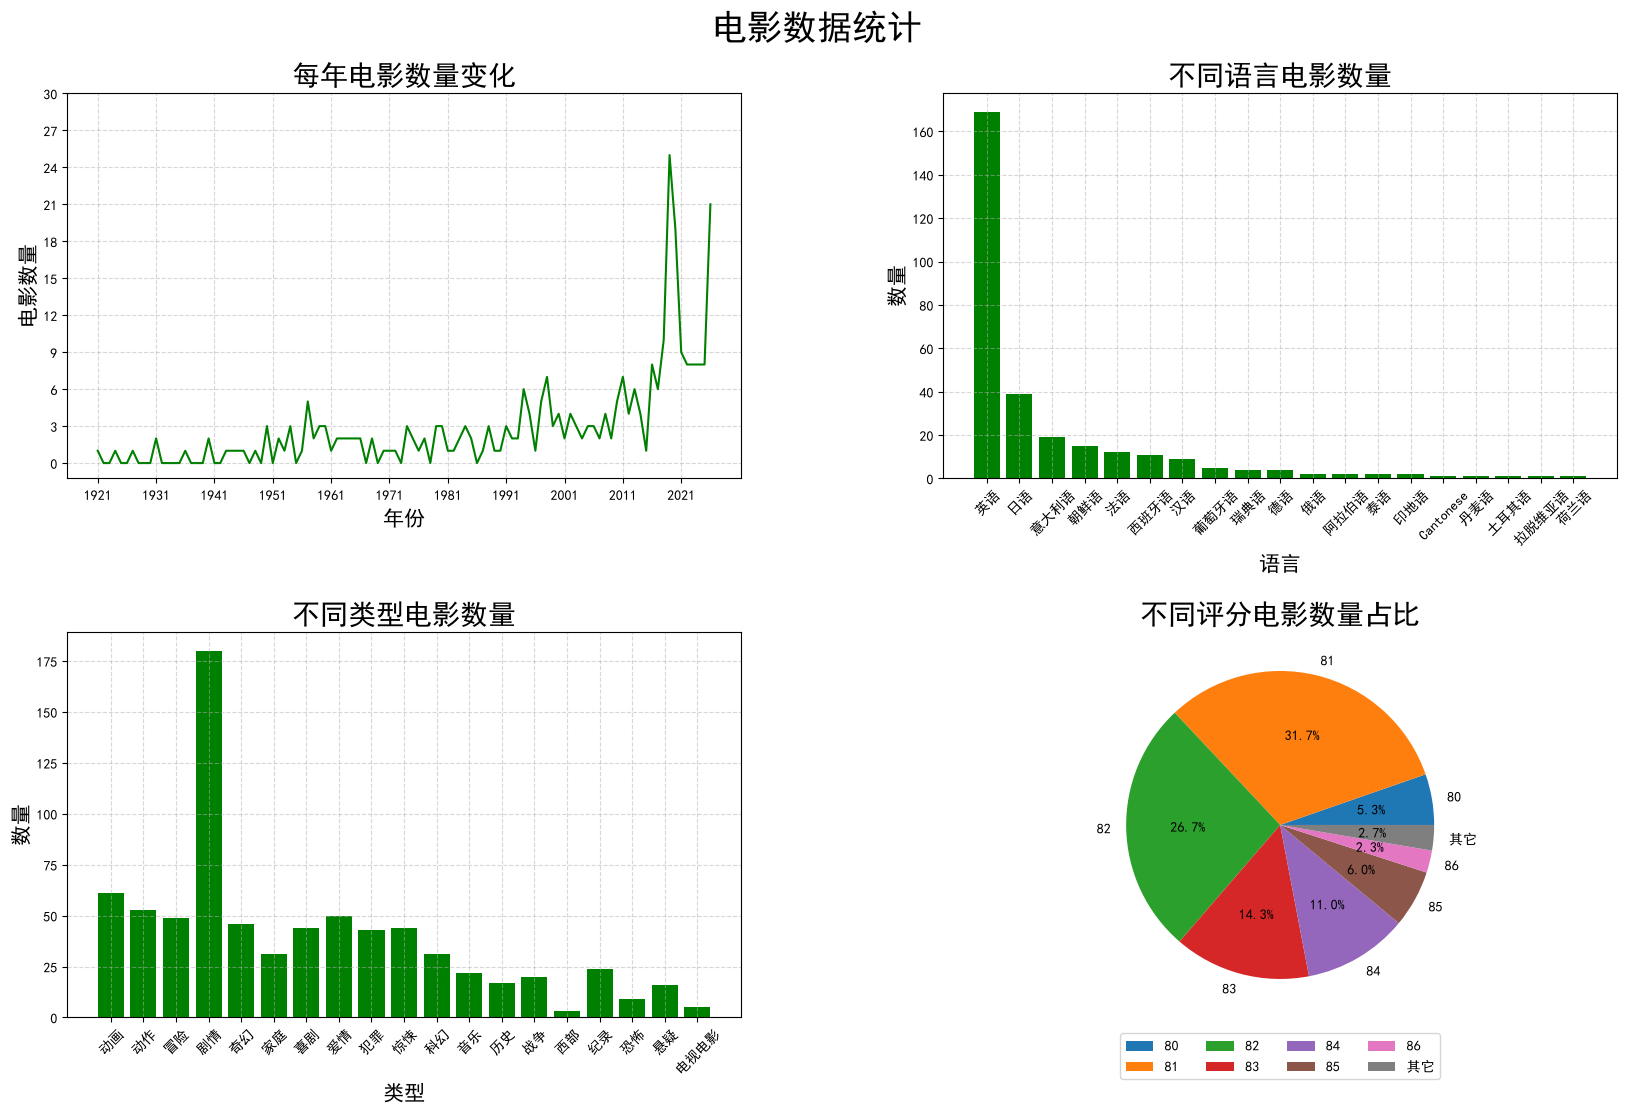

In [47]:
'''
需求1:统计TOP300的电影中,每一年上映的电影数量的变化。(折线图)

需求2:统计对比不同语言电影数量。(柱状图)

需求3:统计对比不同类型电影数量。(柱状图)

需求4:统计对比各个电影评分的比例。(饼状图)
'''
import pandas as pd
import matplotlib.pyplot as plt

# 展示中文
plt.rcParams['font.sans-serif'] = ['SimHei']

# 创建子图
fig, axes = plt.subplots(nrows = 2, ncols=2,figsize=(20, 12), dpi=100)
fig.suptitle('电影数据统计', fontsize=25,y=0.95)   #添加画布标题
fig.subplots_adjust(wspace=0.3, hspace=0.4)

# 获取子图
ax1:plt.Axes = axes[0,0]
ax2:plt.Axes = axes[0,1]
ax3:plt.Axes = axes[1,0]
ax4:plt.Axes = axes[1,1]

# 加载数据
data = pd.read_csv('csv_data/movie_list.csv',usecols = ['电影名','年份','上映时间','评分','语言','类型'])

# 需求1:统计TOP300的电影中,每一年上映的电影数量的变化。(折线图)
# 1.1 数据处理(缺失值，异常值)
# data.isna().sum()   #统计缺失值
# data[data['年份']>2026]     #异常值

# 1.2 分组统计
year_count = data.groupby('年份')['年份'].count()

# 1.3组装数据
# x轴
min_year = year_count.index.min()
max_year = year_count.index.max()
x = [i for i in range(min_year,max_year+1)]
# y轴
y = [int(year_count.get(i,0)) for i in x]

# 1.4 绘制折线图
ax1.plot(x,y,color='green')
ax1.set_title('每年电影数量变化',fontsize=20)
ax1.set_xlabel('年份',fontsize=15)
ax1.set_ylabel('电影数量',fontsize=15)
ax1.set_xticks(x[::10])
y_ticks = [i for i in range(0,31,3)]
ax1.set_yticks(y_ticks)
ax1.grid(linestyle = '--',alpha=0.5)

# 需求2:统计对比不同语言电影数量。(柱状图)
# 2.1 获取数据
language_count = data.groupby('语言')['语言'].count().sort_values(ascending=False)

x_language = language_count.index.tolist()
y_language = language_count.values.tolist()

# 2.2 绘制柱状图
ax2.bar(x_language,y_language,color = 'green',width=0.8)
ax2.set_title('不同语言电影数量',fontsize=20)
ax2.set_xlabel('语言',fontsize=15)
ax2.set_ylabel('数量',fontsize=15)
ax2.grid(linestyle = '--',alpha=0.5)
ax2.tick_params(axis='x',rotation=45)

# 需求3:统计对比不同类型电影数量。(柱状图)
# 3.1 获取数据
type_count = {}
for types in data['类型'].str.split(','):
    for type in types:
        if type not in type_count:
            type_count[type] = 1
        else:
            type_count[type] += 1
x_types = list(type_count.keys())    # 获取x轴数据
y_counts = list(type_count.values())  # 获取y轴数据

# 3.2 绘图
ax3.bar(x_types,y_counts,color = 'green',width=0.8)
ax3.set_title('不同类型电影数量',fontsize=20)
ax3.set_xlabel('类型',fontsize=15)
ax3.set_ylabel('数量',fontsize=15)
ax3.grid(linestyle = '--',alpha=0.5)
ax3.tick_params(axis='x',rotation=45)

# 需求4:统计对比各个电影评分的比例。(饼状图)
# 4.1 数据获取
score_count = data.groupby('评分')['评分'].count()

# 合并小数据（< 2%）
total = score_count.sum()
large_score = score_count.loc[score_count >= total*0.02]
small_score = score_count.loc[score_count < total*0.02]
if small_score.sum() > 0:
    large_score['其它'] = small_score.sum()

scores = large_score.index.tolist()
counts = large_score.values.tolist()

# 4.2 数据可视化
ax4.pie(counts,labels=scores,autopct='%.1f%%')
ax4.set_title('不同评分电影数量占比',fontsize=20)
ax4.legend(loc='center',ncol =4,bbox_to_anchor=(0.5,-0.1),fontsize=10)

# 6. 保存图片
plt.savefig('data/movie_analysis.png')

# 5. 显示
plt.show()

